# Multi-Layered Search: replication notebook

Reproduces the headline numbers and figures of the report from `results/main.csv`. Run from the repository root after `pip install -e ".[dev,analysis]"`. To regenerate the CSV itself (about 10 minutes) run `python -m experiments.run` first.

In [1]:
import sys, csv, math, statistics
from pathlib import Path
sys.path.insert(0, 'src')
from experiments import analyze
rows = analyze.load(Path('results/main.csv'))
analyze.attach_ratios(rows)
summary = analyze.summarise(rows)
print(len(rows), 'query rows;', len(summary), 'size x planner groups')

9240 query rows; 58 size x planner groups


## 1. The brief's example on Figure 1
Flat A* and the two-tier planner both find cost 14; the two-tier route is M > Y > W through the entry cells (3,2) and (7,4).

In [2]:
from mls.grid import Grid
from mls.planners import make
g = Grid.load('maps/figure1.map')
for name, kw in [('astar', {}), ('twotier', {'leg_goal': 'nearest'}), ('twotier-W2', {})]:
    p = make(name, **kw); p.prepare(g); r = p.plan((0, 0), (7, 7))
    print(f"{p.name:>18}: cost {r.cost:g}, {r.expanded} expanded", r.extra.get('areas', ''))
print(g.render(r.path, (0, 0), (7, 7)))

             astar: cost 14, 14 expanded 
twotier-W1-nearest: cost 14, 16 expanded [0, 2, 4]
        twotier-W2: cost 14, 36 expanded [0, 2, 4]
PPP#WWWG
PPPWWWW*
PPP#WWW*
#P#####*
MMM#Y#Y*
MM******
MM*##B##
S**#BBB#


## 2. Scaling table (generated maps)

In [3]:
by = {(s['size'], s['planner']): s for s in summary}
print(f"{'size':>5} {'A* nodes':>10} {'W1 nodes':>9} {'saving':>7} {'A* ms':>7} {'W1 ms':>6} {'W1 ratio':>9}")
for n in sorted({s['size'] for s in summary}):
    a, w = by[(n, 'astar')], by[(n, 'twotier-W1')]
    print(f"{n:>5} {a['nodes_mean']:>10.0f} {w['nodes_mean']:>9.0f} {a['nodes_mean']/w['nodes_mean']:>6.1f}x {a['runtime_ms_mean']:>7.2f} {w['runtime_ms_mean']:>6.2f} {w['ratio_mean']:>9.3f}")

 size   A* nodes  W1 nodes  saving   A* ms  W1 ms  W1 ratio
   16         23        22    1.0x    0.05   0.10     1.012
   32        123        43    2.9x    0.24   0.20     1.013
   64        330        81    4.1x    0.68   0.41     1.010
  128       1254       166    7.6x    2.87   1.07     1.012
  256       5178       322   16.1x   13.32   2.42     1.010
  512      16922       626   27.0x   58.31   8.09     1.009


## 3. Figures
Regenerates every figure into `results/figures/` and shows the two main ones.

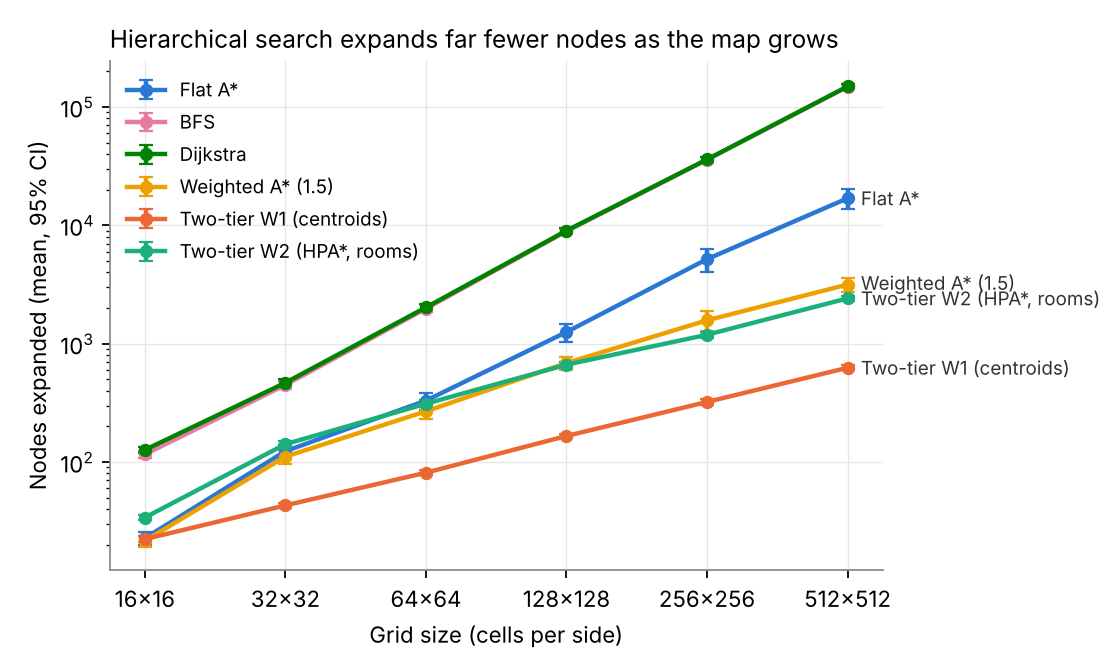

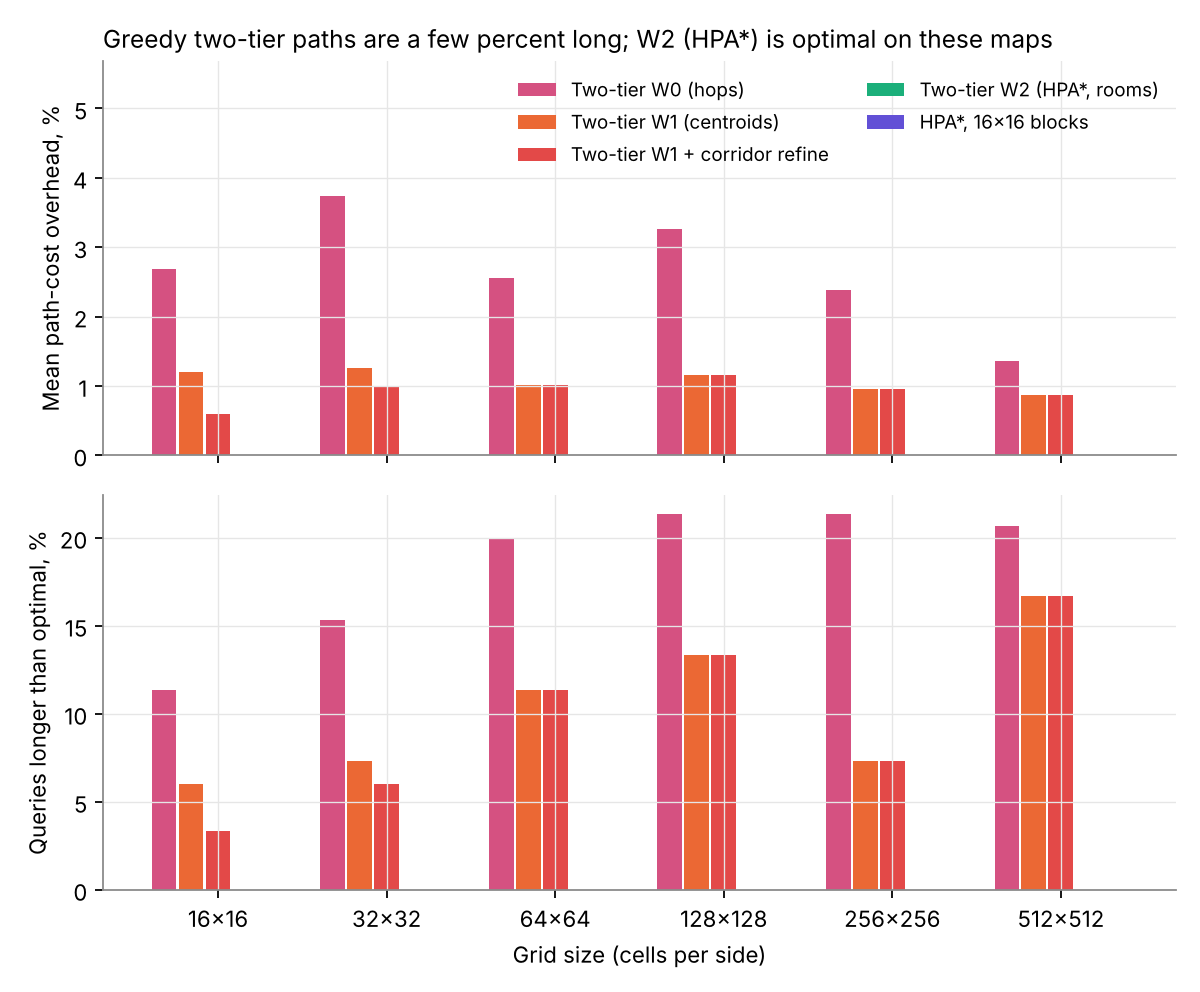

In [4]:
prep = list(csv.DictReader(open('results/prep.csv')))
analyze.figures(rows, summary, prep, Path('results/figures'))
from IPython.display import Image, display
display(Image('results/figures/nodes_vs_size.png'))
display(Image('results/figures/cost_overhead.png'))

## 4. Ablation, crossover, distance buckets and paired tests
The Markdown tables used in the report.

In [5]:
analyze.write_ablation(rows, 128, Path('results/ablation.md'))
analyze.write_crossover(summary, Path('results/crossover.md'))
analyze.write_distance_buckets(rows, Path('results/distance_buckets.md'))
analyze.write_paired_tests(rows, Path('results/paired_tests.md'))
for f in ['ablation', 'crossover', 'distance_buckets', 'paired_tests']:
    print(open(f'results/{f}.md').read())

Ablation at 128x128 (generated maps). Cost ratio relative to flat A* on the same query.

| Variant | Weight model | Leg goal | Post-process | Nodes (mean) | Cost ratio mean | p95 | max | Runtime ms |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Flat A* | - | - | - | 1254 | 1.000 | 1.000 | 1.000 | 2.87 |
| Weighted A* (1.5) | - | - | - | 686 | 1.010 | 1.052 | 1.107 | 1.59 |
| Two-tier W0 (hops) | W0 hops | first cell | none | 227 | 1.033 | 1.217 | 1.526 | 0.67 |
| Two-tier W1 (centroids) | W1 centroid | first cell | none | 166 | 1.012 | 1.075 | 1.310 | 1.07 |
| Two-tier W1, nearest-entry legs | W1 centroid | nearest entry | none | 166 | 1.012 | 1.075 | 1.310 | 0.84 |
| Two-tier W1 + corridor refine | W1 centroid | first cell | corridor refine r=2 | 430 | 1.012 | 1.075 | 1.310 | 2.23 |
| Two-tier W2 (HPA*, rooms) | W2 portal dist. | chosen portal | none | 664 | 1.000 | 1.000 | 1.000 | 1.22 |
| HPA*, 16x16 blocks | W2 on 16x16 blocks | chosen portal | none | 680 | 1.000 | 1.0

## 5. The warehouse map: where the greedy planner struggles
W1 paths are 11% longer on average here because the cross-aisles are long thin areas; W2 is optimal.

       astar: nodes   55.8  cost ratio mean 1.000 max 1.000
  twotier-W1: nodes   52.4  cost ratio mean 1.108 max 1.957
  twotier-W2: nodes  253.7  cost ratio mean 1.000 max 1.000
   wastar1.5: nodes   53.7  cost ratio mean 1.011 max 1.045


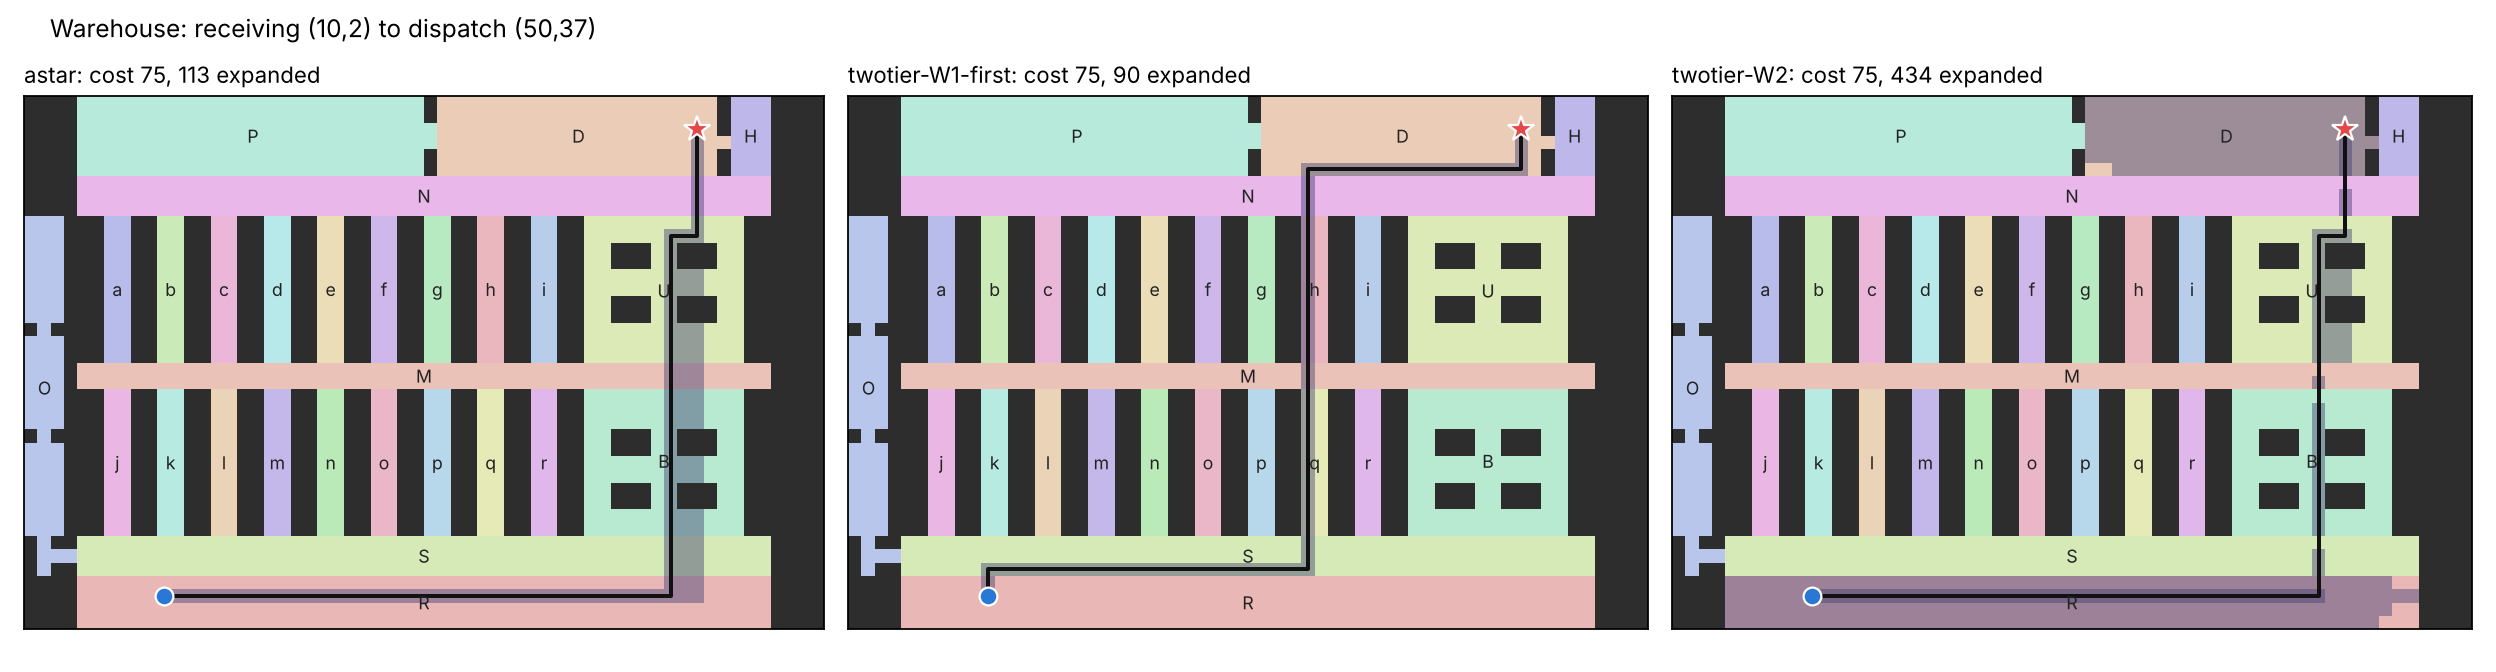

In [6]:
wh = [r for r in rows if r['map'] == 'warehouse']
for p in ['astar', 'twotier-W1', 'twotier-W2', 'wastar1.5']:
    rs = [r for r in wh if r['planner'] == p]
    ra = [r['ratio'] for r in rs]
    print(f"{p:>12}: nodes {statistics.mean(r['expanded'] for r in rs):6.1f}  cost ratio mean {statistics.mean(ra):.3f} max {max(ra):.3f}")
display(Image('results/figures/warehouse_demo.png'))